# Final report — missing pieces

The analyses the work still lacked after the model sequence, the ablations and the extrapolations, one section per item.
**Part A** needs no retraining (references, real-data properties, the learned rule, replications, rollout noise,
provenance, intervals, the centroid choice, multi-fish extras, robustness numbers); **Part B** retrains (leave one
condition out, the main line at seed 101, a capacity check).

Headline models: **M6** = the analysis model (key 26e at seed 0, 30d at seed 101); **F** = the final model (14f / 32b).
Seed 0 and seed 101 are different cross-validation splits: never pooled, a claim needs the same direction at both.
Every AUC is the classifier test on held-out fish with the **matched** windowing unless stated (0.5 = indistinguishable;
real against real ≈ 0.52). Likelihoods are held-out bits per bout (lower = better).

Code: `scripts/missing_pieces.py` (computations, cached in `Model/missing_pieces/`), `scripts/multi_stim.py`,
`scripts/multi_fish.py`; the retrained units are Model 34 in `report_models.py` (keys 34a–34j).

## Findings in short

Values are seed 0 / seed 101 unless stated. "Beyond the noise" means the same sign at both seeds with an interval that
excludes zero.

**Part A**

1. **Realism now has a scale.** On the matched windowing, the classifier separates real fish from:
   - their own bouts in random order: AUC 1.00;
   - the classical 3-state HMM: 1.00, and 0.99 on turn, step and interval alone;
   - their own bouts in random blocks of 10: 0.86;
   - their own bouts in random blocks of 30: 0.67.

   M6 scores 0.67 / 0.65 and F 0.64 / 0.64; real against real is 0.50. So the models are about as hard to tell from a
   fish as **the fish's own data cut into 30-bout pieces**. Without the position features they do better than that
   (M6 0.60 / 0.57 and F 0.56 / 0.56, against 0.66).

   On likelihood:
   - The models save **0.80–0.84 bits per bout** over pooled population marginals of the three heads.
   - They save **0.15–0.19 bits per bout** on the turn alone over the stimulus-aware HMM.
   - Both hold at both seeds, with intervals over fish well away from zero.
   - The classical HMMs barely beat a plain marginal (7.82–7.83 against 7.85 bits).
2. **What still gives the models away.** Both models match real fish within the per-fish intervals on:
   - the bout marginals (median and 90th percentile of turn, step and interval);
   - the wall law (turning toward the centre: 0.57 near the centre to 0.79 at the wall);
   - where in the dish the fish swims (median r/R 0.45).

   The systematic differences:
   - M6's interval correlations at lags 4–5 are too low (−0.05 to −0.06): slow persistence in timing is missing.
   - F's turns are slightly too persistent (+0.03 at lags 1–5, both seeds).

   The classifier uses dish position most (share of bouts near the wall, median radius), then interval timing.
   Simulated fish sit at the edge of the cloud of real individuals: their distance to the nearest real fish is
   0.83–0.86, against 0.84 between real fish.
3. **The learned rule** (toward-turn on matched geometry, real first):
   - **Steady pull, moving dots:** real 19.3°, M6 19.0–19.5° (matches), F 21.5–22.4°.
   - **Onset pull, first 4 s:** real 35.7°, M6 25.6–26.0°, F 30.9–31.1°. F's correction closes half the gap.
   - **Count step:** real 6.6°, M6 4.8°, F 6.0°.
   - **Strongest pull:** at 10–20 mm in both models, against 20–35 mm in real fish.
   - **Very close range:** real fish turn *away* from a single dot closer than 10 mm; neither model does.
4. **The extrapolations replicate.**
   - **Two dot groups:** every pattern holds on all five models and seeds (M6+C, F, M6 at seed 0; M6 and F at
     seed 101):
     - with two identical groups on opposite sides, "effects" ends between them in 44–48 % of trials (like no
       stimulus) while "nearest" commits (18–23 % between);
     - at equal distance the 8 dots win over 2 under both rules;
     - with 2 dots near and 8 far, "effects" still favours the 8 while "nearest" takes the near 2;
     - moving beats static everywhere.
   - **Multi-fish:** shoaling holds for M6 and F at both seeds:
     - pair attraction index +0.32 to +0.35;
     - groups of 10: D −0.18 to −0.20;
     - groups of 5: D −0.30 / −0.30 for F;
     - 5× dish, F seed 101: D −0.71, shoals of 8.7 fish on average, two fish travelling 4.6 m per hour within 25 mm
       of each other against 1.2 m by chance.
5. **Rollout noise, and F against M6.**
   - **One profile reading moves by:** 0.1–0.4 mm on the dip, 0.6–0.9 mm on the grading, 0.02–0.15 SEM on the
     moving error, 0.3–0.8 mm on attraction. Stream 0 reproduces every archived number exactly.
   - **F's deeper dip is beyond the noise at both seeds:** +0.4 / +0.6 mm, 4-stream means.
   - **Its moving-error advantage holds at seed 0 only; the grading differences are within noise.**
   - **M6's archived seed-0 dip (3.70 mm) is its luckiest stream:** the other three give 2.7–3.1 mm.
6. **Provenance.** The current segmentation code finds the same 71,933 bouts, with identical turns and steps. The
   uncommitted onset change shifts the timing of about 4 % of bouts (interval change > 0.04 s); every median is
   unchanged.
7. **Paired-by-fish intervals.**
   - **Beyond the noise at both seeds:**
     - the per-fish latent: −0.06 / −0.11 bits;
     - the slow drift: −0.05 to −0.06;
     - kinematic history: +0.28 / +0.32 bits without it, +0.04 with one lag instead of three.
   - **F against M6:** −0.041 [−0.079, −0.004] / −0.030 [−0.078, +0.011]. The turn head is better at both seeds;
     the joint likelihood is better at seed 0 only.
   - **Removing the stimulus:** costs turn likelihood at both seeds, but its joint cost crosses zero at seed 0.
   - **No significant change:** without group size, with 64 hidden units, or trained without 6 moving dots.
8. **The centroid is the right target.** When the centroid and the nearest dot lie on opposite sides of the fish,
   real fish turn toward the centroid 67 % of the time and toward the nearest dot 33 % (+0.34 [0.29, 0.39], 15 fish,
   1,780 bouts, moving dots). With static dots there is no preference. The centroid and a 1/r-weighted centroid almost
   never disagree.
9. **Multi-fish extras.**
   - **No short-range repulsion:** neighbour density peaks on top of each fish, whereas real juveniles keep a gap of
     5–15 mm (Kappel et al. 2022).
   - **5× dish, random directions:** the shoaling disappears (D −0.06; travelling together 0.30 m per pair-hour =
     chance). It is directed attraction.
   - **Onset clock restarted whenever a neighbour comes into view** (so F's correction acts): shoaling is unchanged
     (D −0.74).
10. **Robustness.**
    - **Without the centroid-outside-dish filter**, real fish show a 3.79 mm dip and 8.59 mm grading. The models stay
      shallower (2.4–3.0 mm) and less graded (4.9–7.1 mm), so the deficits are not an artefact of the filter.
    - **The real-vs-real floor without radial features** is 0.50.
    - **Profile, attraction and two-group millimetres** use 3.67 px/mm; multiply by 1.0194 for the thesis scale of
      3.60.

**Part B**

11. **Leave one condition out.** Trained without ever seeing 6 moving dots, M6 predicts those bouts almost as well as
    when trained on them: +0.012 [−0.011, +0.031] / +0.023 [−0.007, +0.054] bits per bout. That is within the
    retraining differences on the conditions both models saw, with AUC unchanged (0.66 / 0.63). Its 6-dot attraction
    is 4.7 / 4.6 mm, against 4.9 / 6.4 for M6 and 6.4 for real fish: a good prediction at seed 0, low at seed 101.
12. **The main line at seed 101.**
    - **Wall rejection** (0.86 → 0.83) and **the per-fish latent** (0.83 → 0.71) replicate their seed-0 steps.
    - **M3 → M4** is small at both seeds (−0.03 / −0.005).
    - **M5+T** again buys a deeper dip (+0.3 mm) at a slightly worse AUC.
13. **Capacity.**
    - **256 hidden units are worse:** +0.07 / +0.03 bits, AUC 0.73 / 0.69 — they overfit.
    - **64 units tie 128 units:** +0.02 / −0.02 bits, AUC 0.71 / 0.66. They often run into the epoch limit.

    One hidden layer of 128 is a sound choice.

## Contents

**Part A**
1. [Realism scale: reference generators and classical baselines](#s1)
2. [What still gives the models away](#s2)
3. [The learned rule: response maps and a compact summary](#s3)
4. [The extrapolations replicated](#s4)
5. [Rollout-stream noise, and F against M6](#s5)
6. [Data provenance](#s6)
7. [Paired-by-fish intervals on the key likelihood differences](#s7)
8. [Which point of a dot group the fish turns toward](#s8)
9. [Multi-fish extras](#s9)
10. [Robustness numbers](#s10)

**Part B**
11. [Leave one condition out: predicting 6 moving dots](#s11)
12. [The main line at seed 101](#s12)
13. [Capacity: 64 and 256 hidden units](#s13)

In [ ]:
# Setup: everything below reads saved results (scripts/missing_pieces.py caches, report_outputs/, multi_stim/, multi_fish/).
import sys, json, glob
sys.path.insert(0, "."); sys.path.insert(0, "../scripts")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
import missing_pieces as P

def S(key):
    """The saved key numbers of a notebook unit (report_outputs/summary_M<key>.json), or {}."""
    return P.summary(key) or {}

<a id="s1"></a>
## 1. Realism scale: reference generators and classical baselines

**Question.** How good is a matched AUC of
~0.64? The classifier needs a scale: what does it give for generators that are obviously not the fish's model?

**What was done.** Each reference re-orders *real* bouts, every bout keeping all its attributes (turn, step, interval,
distance to the dots, position in the dish), and is cut at the real fish's own window positions (the matched windowing,
8 replicates per fish, the same classifier as the models):
- **shuffled** — the fish's own bouts in random order (its exact marginals and individuality, no sequence);
- **block L** — the fish's own bouts in random blocks of L = 3 / 10 / 30 consecutive bouts (short-range sequence kept);
- **pooled** — bouts drawn at random from the other 14 fish (a population marginal, no individuality, no sequence);
- **hmm** — turns from a 3-state hidden Markov model (the classical bout model, Dommanget-Kott-style; fitted on the
  training fish of each fold), every other attribute from a random bout of the other 14 fish.

**How to read.** A reference that keeps more of the real structure is harder to detect. The models are read against this
ladder; the *three heads* column (turn, step and interval only, no position or dot distance) is the fairest for the HMM,
which has no space. The likelihood table puts the same classical models (and a pooled-marginal density of all three
heads) on the models' exact folds.

In [ ]:
# Matched C2ST AUC of the reference generators, the real-vs-real floor and the four headline models (same windows, same
# classifier). se = across the 8 replicates.
R = P.load("refs")["table"]
print(R[["all features", "all features se", "no radial", "no radial se", "three heads", "three heads se"]].round(3).to_string())

                                           all features  all features se  no radial  no radial se  three heads  three heads se
generator                                                                                                                     
shuffled                                          1.000            0.000      1.000         0.000        0.895           0.002
block3                                            0.991            0.000      0.991         0.001        0.749           0.002
block10                                           0.863            0.003      0.850         0.003        0.701           0.002
block30                                           0.669            0.005      0.658         0.006        0.618           0.006
pooled                                            1.000            0.000      1.000         0.000        0.986           0.000
hmm                                               1.000            0.000      1.000         0.000        0.985 

In [ ]:
# The model sequence on the same reading (matched AUC, all features | no radial), from the saved units. M1-M3 and M5+T
# at seed 101 are the new Part B units (section 12).
rows = []
for name, k0, k1 in [("M1", "1", "34a"), ("M2", "2", "34b"), ("M3", "3", "34c"), ("M4", "20f", "30a"), ("M5", "25d", "30b"),
                     ("M5+R", "29a", "30c"), ("M5+T", "29b", "34d"), ("M6", "26e", "30d"), ("F", "14f", "32b"),
                     ("M6 without stimulus", "29e", "33u"), ("M6 latent frozen", "33q", "33r")]:
    a, b = S(k0), S(k1)
    rows.append({"model": name, "matched s0": a.get("auc_matched"), "matched s101": b.get("auc_matched"),
                 "no radial s0": a.get("auc_matched_norad"), "no radial s101": b.get("auc_matched_norad")})
print(pd.DataFrame(rows).set_index("model").round(3).to_string())

                     matched s0  matched s101  no radial s0  no radial s101
model                                                                      
M1                        0.869         0.861         0.837           0.822
M2                        0.839         0.832         0.832           0.824
M3                        0.701         0.708         0.666           0.669
M4                        0.669         0.703         0.618           0.676
M5                        0.648         0.673         0.590           0.641
M5+R                      0.722         0.753         0.662           0.722
M5+T                      0.692         0.685         0.615           0.624
M6                        0.671         0.645         0.599           0.574
F                         0.641         0.643         0.561           0.555
M6 without stimulus       0.785         0.757         0.743           0.685
M6 latent frozen          0.873         0.812         0.866           0.790


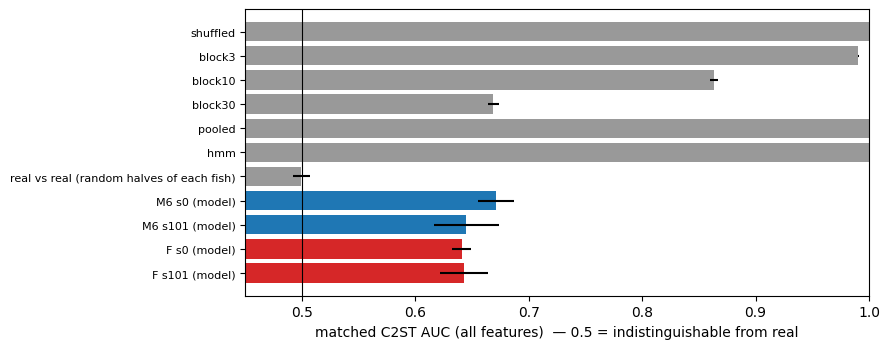

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.6))
R = P.load("refs")["table"]
lab = list(R.index)
ax.barh(range(len(lab)), R["all features"], xerr=R["all features se"], color=["0.6"] * (len(lab) - 4) + ["C0", "C0", "C3", "C3"])
ax.axvline(0.5, color="k", lw=0.8)
ax.set_yticks(range(len(lab))); ax.set_yticklabels(lab, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("matched C2ST AUC (all features)  — 0.5 = indistinguishable from real")
ax.set_xlim(0.45, 1.0); plt.tight_layout()

In [ ]:
P.baselines_table().round(4)

                                          turn      step  interval      joint saved_vs_pooled_joint     saved_vs_hmm_turn
seed model                                                                                                               
0    pooled marginal (turn)             7.8395                                                                           
     marginal (turn)                    7.8475                                                                           
     HMM, 3 states (turn)               7.8345                                                                           
     HMM + stimulus (turn)              7.8176                                                                           
     pooled marginal (all three heads)  7.8395  4.821883   1.52157  14.182922                                            
     M6 s0                              7.6653  4.504569  1.214955  13.384777  0.798 [0.668, 0.967]  0.152 [0.118, 0.181]
     F s0               

<a id="s2"></a>
## 2. What still gives the models away

**Question.** Where do M6 and F still differ from real fish, on the
properties Chapter 3 establishes, and what does the classifier use to tell them apart?

**What was done.** Two record-anchored rollouts per held-out fish (each fish by the fold model that never saw it):
the bout marginals (median and 90th percentile of |turn|, step, interval; share of near-straight bouts), the
correlations between successive bouts within runs (lags 1–5, |turn|, log step, log interval), the wall law (probability
of turning toward the dish centre by distance from the centre) and where in the dish the fish swims. Then the
classifier's permutation importances on the matched windows, and the nearest-real-neighbour distance (is each
simulated fish inside the cloud of real individuals?).

**How to read.** Differences are model − real per fish, mean over the 15 fish with a 95 % bootstrap interval over fish.

In [ ]:
P.properties_table().round(3)

                   real   M6 s0     M6 s0 - real [95% CI]  M6 s101   M6 s101 - real [95% CI]    F s0     F s0 - real [95% CI]  F s101    F s101 - real [95% CI]
property                                                                                                                                                       
turn_median      37.874  35.317   -2.557 [-7.179, +2.250]   38.252   +0.378 [-3.948, +5.028]  37.214  -0.659 [-5.116, +3.537]  35.646   -2.228 [-6.578, +2.278]
turn_q90         88.329  82.108  -6.221 [-17.970, +3.081]   88.517  +0.189 [-10.879, +8.698]  87.249  -1.080 [-9.250, +5.729]  87.149  -1.179 [-12.882, +7.164]
straight          0.036   0.043   +0.007 [-0.007, +0.018]    0.037   +0.001 [-0.014, +0.014]   0.039  +0.004 [-0.009, +0.016]   0.046   +0.010 [-0.002, +0.021]
step_median       4.262   3.944   -0.318 [-0.772, +0.132]    4.487   +0.225 [-0.308, +0.755]   4.218  -0.044 [-0.463, +0.354]   4.178   -0.084 [-0.581, +0.403]
step_q90          6.927   6.390   -0.537

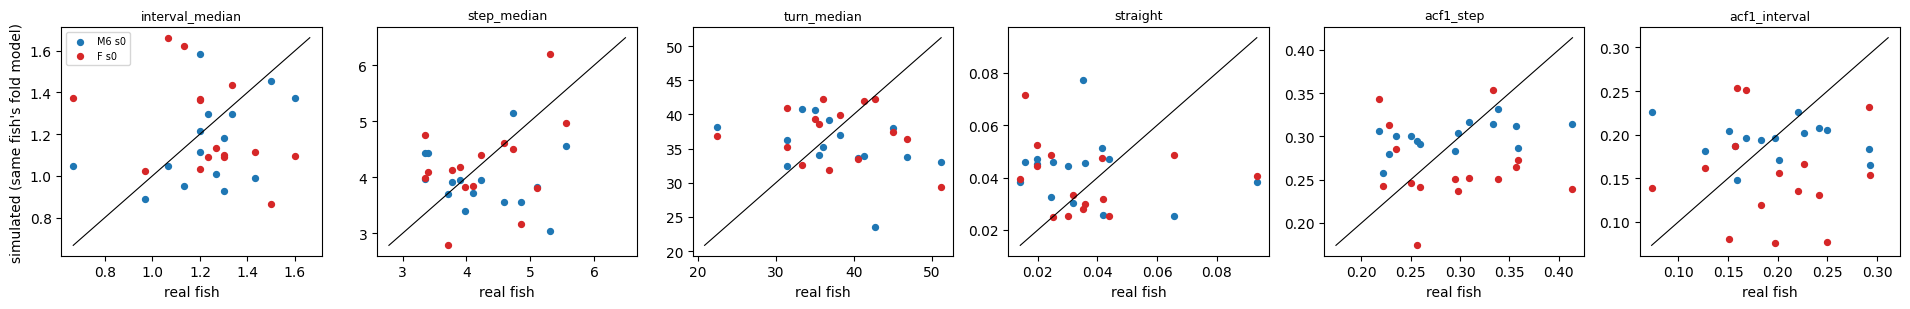

In [ ]:
# One point per fish: real (x) against simulated (y), M6 and F at seed 0.
T = P.load("properties"); per = T.groupby(["model", "fish"]).mean(numeric_only=True)
props = ["interval_median", "step_median", "turn_median", "straight", "acf1_step", "acf1_interval"]
fig, axes = plt.subplots(1, len(props), figsize=(3.2 * len(props), 3.2))
for ax, p in zip(axes, props):
    r = per.loc["real", p]
    for lab, col in (("M6 s0", "C0"), ("F s0", "C3")):
        ax.scatter(r, per.loc[lab, p].reindex(r.index), s=18, color=col, label=lab)
    lo, hi = np.nanmin([r.min(), per[p].min()]), np.nanmax([r.max(), per[p].max()])
    ax.plot([lo, hi], [lo, hi], color="k", lw=0.8); ax.set_title(p, fontsize=9); ax.set_xlabel("real fish")
axes[0].set_ylabel("simulated (same fish's fold model)"); axes[0].legend(fontsize=7)
plt.tight_layout()

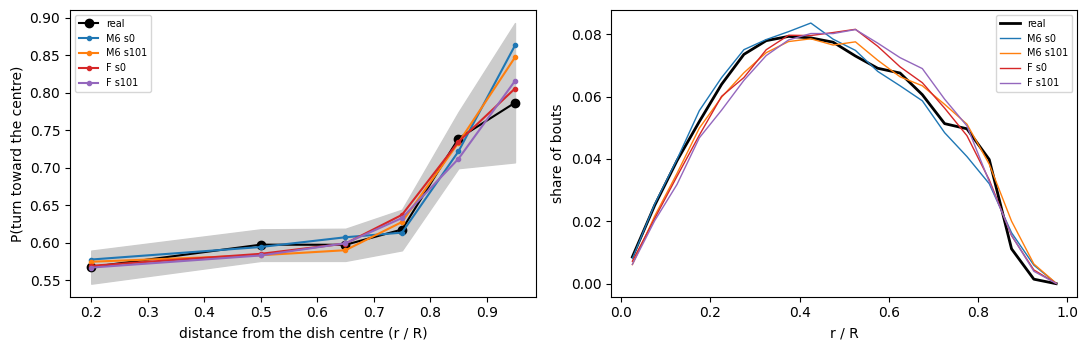

In [ ]:
# The wall law and where in the dish the fish are: real (mean +- 95 % CI over fish) against the models.
T = P.load("properties"); per = T.groupby(["model", "fish"]).mean(numeric_only=True)
wc = [c for c in per.columns if c.startswith("wall_")]
x = [np.mean([float(v) for v in c[5:].split("-")]) for c in wc]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
r = per.loc["real", wc]
ci = np.array([P._boot_ci(r[c].dropna().values) for c in wc])
a1.fill_between(x, ci[:, 0], ci[:, 1], color="0.8"); a1.plot(x, r.mean(), "k-o", label="real")
for lab, col in zip(P.HEAD, ("C0", "C1", "C3", "C4")):
    a1.plot(x, per.loc[lab, wc].mean(), "-o", color=col, ms=3, label=lab)
a1.set_xlabel("distance from the dish centre (r / R)"); a1.set_ylabel("P(turn toward the centre)"); a1.legend(fontsize=7)
H = T[T.rep == 0].groupby("model").radial_hist.apply(lambda s: np.mean(np.stack(s.values), 0))
edges = P.RAD_BINS; mid = (edges[1:] + edges[:-1]) / 2
for lab, col in [("real", "k")] + list(zip(P.HEAD, ("C0", "C1", "C3", "C4"))):
    a2.plot(mid, H[lab], color=col, lw=2 if lab == "real" else 1, label=lab)
a2.set_xlabel("r / R"); a2.set_ylabel("share of bouts"); a2.legend(fontsize=7)
plt.tight_layout()

In [ ]:
# What the matched classifier uses: permutation importance (drop in held-out AUC when a feature is shuffled), top 12.
I = P.load("importances")
print(I.assign(mean=I.mean(1)).sort_values("mean", ascending=False).head(12).round(4).to_string())

                M6 s0  M6 s101    F s0  F s101    mean
rad_frac_wall  0.0344   0.0579  0.0306  0.0062  0.0323
rad_median     0.0133   0.0093  0.0196  0.0193  0.0154
dt_median     -0.0022   0.0232  0.0101  0.0260  0.0143
rad_q90        0.0098   0.0207  0.0113  0.0054  0.0118
rad_mean       0.0099   0.0038  0.0150  0.0176  0.0116
dt_std         0.0102   0.0096  0.0066  0.0034  0.0074
dt_acf1        0.0152   0.0088  0.0007  0.0046  0.0073
dt_mean       -0.0089   0.0151  0.0053  0.0058  0.0044
T_RL           0.0016   0.0063  0.0027  0.0055  0.0040
absdth_std     0.0004   0.0092 -0.0026  0.0064  0.0034
dist_acf1      0.0090   0.0048 -0.0002 -0.0022  0.0029
T_LF           0.0055   0.0041 -0.0005  0.0019  0.0028


In [ ]:
# Nearest real neighbour: is a simulated fish as close to some real fish as real fish are to each other?
N = P.load("nearest")
for lab, v in N.items():
    print(f"== {lab}")
    print("\n".join(l for l in v["text"].splitlines() if l.strip().startswith(("real fish", "sampled fish", "mean distance", "the sampled"))))
    print("feature-drop AUC, PLAIN harness windowing (not matched; section 1 has the matched readings):")
    print(v["drop"].round(3).to_string())

== M6 s0
  real fish    -> nearest OTHER real fish: mean 0.838  se 0.019  median 0.843  10th-90th pct 0.756-0.942   (n = 15)
  sampled fish -> nearest real fish:       mean 0.857  se 0.008  median 0.857  10th-90th pct 0.739-0.978   (n = 120)
  mean distance to ALL real fish: real 0.960, sampled 0.968
  sampled fish whose nearest real fish is closer than the median real fish's (0.843): 54 / 120  (a population exactly inside the cloud: ~60)
  the sampled fish's nearest real fish is the one it was rolled out for: 6%  (chance 7%)
feature-drop AUC, PLAIN harness windowing (not matched; section 1 has the matched readings):
                                all  all_se  no radial  no radial_se  three heads  three heads_se  turn only  turn only_se
arm                                                                                                                       
S4x_adt_z2_cdt_tr_rc_al_w3ft  0.679   0.017       0.62         0.021        0.605            0.02      0.578         0.018
== M6 

<a id="s3"></a>
## 3. The learned rule: response maps and a compact summary

**Question.** What rule did the model learn for
turning toward the dots, as a function of where they are, how many, whether they move and how long ago they appeared —
and is it the real fish's rule?

**What was done.** On every bout of every held-out fish, the model's teacher-forced expected turn (its prediction from
the real history and the real stimulus, population latent) next to the fish's real turn, both as a **toward-turn**
(turn × sign of the dots' bearing, deg). Binned by |bearing| × range, per count, motion and phase of the block. Then
five numbers per source on matched geometry (|bearing| 45–135°): the onset gain (first 4 s, moving, 10–35 mm), the
steady gain (≥ 10 s), the range of the strongest steady pull, the count step (2–8 dots minus 1 dot) and the static gain.

**How to read.** Real and model maps are on the same bouts, so a difference is the fitted rule's error, not sampling.

In [ ]:
P.law_summary().round(2)

     model   source  onset_gain  steady_gain peak_range  count_step  static_gain
0    M6 s0     real       35.66        19.27   (20, 35]        6.55         2.32
1    M6 s0    M6 s0       25.64        18.98   (10, 20]        4.85         3.57
2  M6 s101     real       35.66        19.27   (20, 35]        6.55         2.32
3  M6 s101  M6 s101       26.00        19.48   (10, 20]        4.79         2.83
4     F s0     real       35.66        19.27   (20, 35]        6.55         2.32
5     F s0     F s0       30.92        21.47   (10, 20]        6.06         3.33
6   F s101     real       35.66        19.27   (20, 35]        6.55         2.32
7   F s101   F s101       31.12        22.42   (10, 20]        6.03         2.85


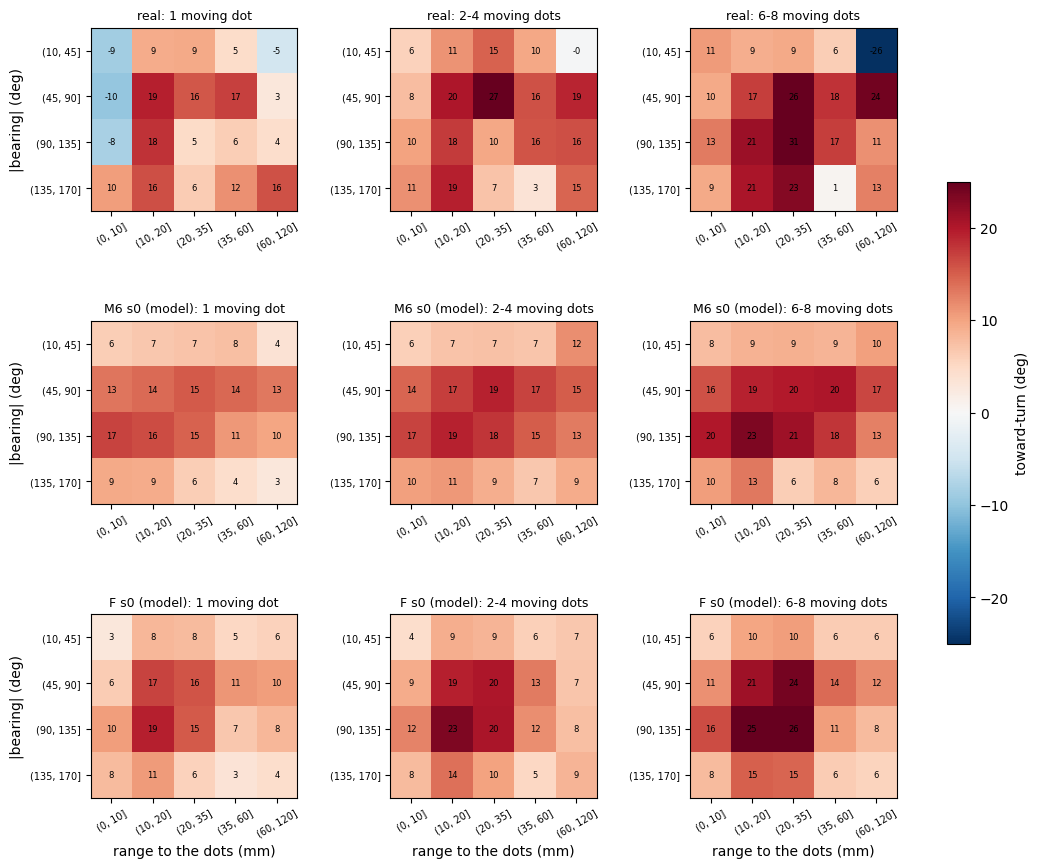

In [ ]:
# Toward-turn (deg): |bearing| (rows) x range (columns), moving dots, >= 10 s into the block, per fish then over fish.
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
fig.subplots_adjust(hspace=0.6, wspace=0.45)
for j, (n, title) in enumerate((((1,), "1 moving dot"), ((2, 4), "2-4 moving dots"), ((6, 8), "6-8 moving dots"))):
    real, m6 = P.law_maps("M6 s0", True, n)
    _, f = P.law_maps("F s0", True, n)
    for i, (M, lab) in enumerate(((real, "real"), (m6, "M6 s0 (model)"), (f, "F s0 (model)"))):
        ax = axes[i, j]
        im = ax.imshow(M.values, cmap="RdBu_r", vmin=-25, vmax=25, aspect="auto")
        ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([str(c) for c in M.columns], fontsize=7, rotation=30)
        ax.set_yticks(range(M.shape[0])); ax.set_yticklabels([str(c) for c in M.index], fontsize=7)
        ax.set_title(f"{lab}: {title}", fontsize=9)
        for (a, b), v in np.ndenumerate(M.values):
            if np.isfinite(v):
                ax.text(b, a, f"{v:.0f}", ha="center", va="center", fontsize=6)
for ax in axes[-1]:
    ax.set_xlabel("range to the dots (mm)")
for ax in axes[:, 0]:
    ax.set_ylabel("|bearing| (deg)")
fig.colorbar(im, ax=axes, shrink=0.6, label="toward-turn (deg)")

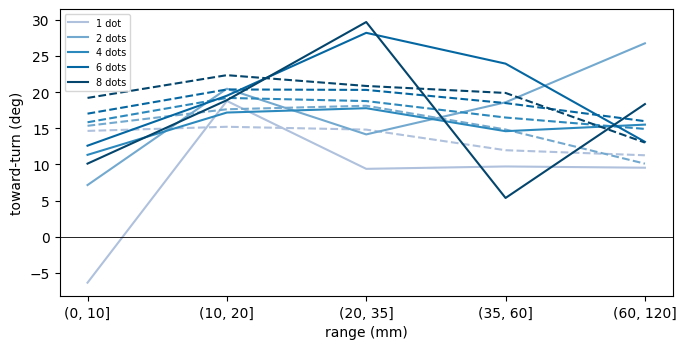

In [ ]:
# Toward-turn against range by dot count, real (solid) vs M6 (dashed), moving dots, |bearing| 45-135 deg, >= 10 s.
t = P._toward_cols(P.load("laws"))
g = (np.degrees(np.abs(t.phi)) >= 45) & (np.degrees(np.abs(t.phi)) <= 135) & t.moving & (t.phase == ">= 10 s") & (t.model == "M6 s0")
fig, ax = plt.subplots(figsize=(7, 3.6))
for n, col in zip((1, 2, 4, 6, 8), plt.get_cmap("PuBu")(np.linspace(0.35, 0.95, 5))):
    s = t[g & (t.n == n)]
    for c, ls in (("tow_real", "-"), ("tow_model", "--")):
        v = s.groupby(["fish", "range"], observed=True)[c].mean().groupby("range", observed=True).mean()
        ax.plot([str(i) for i in v.index], v.values, ls, color=col, label=f"{n} dot{'s' if n > 1 else ''}" if c == "tow_real" else None)
ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("range (mm)"); ax.set_ylabel("toward-turn (deg)"); ax.legend(fontsize=7)
plt.tight_layout()

<a id="s4"></a>
## 4. The extrapolations replicated

**Question.** Do the two extrapolations (two dot groups at once; several
fish seeing each other) hold on M6 itself and at the second seed, as the claim rule requires?

**What was done.** The two-group scenes (v2: references, mirror pairs) re-run on M6 at both seeds (26e, 30d) and on F at
seed 101 (32b), next to the original M6+C (28b) and F seed 0 (14f). The multi-fish runs repeated on M6 at both seeds
(pairs, groups of 10) and, for F at seed 101, on the 5× dish, the random-direction control and groups of 5.

**How to read.** A pattern is claimed only if it has the same sign for every model and seed.

In [ ]:
# Two groups: key readouts per model (fish-level means). P_between = share of trials ending between the groups;
# pref = P(choose A) - P(choose B) (A = the first group of the scene).
import multi_stim as MS
tags = [t for t in ("28b", "14f", "26e", "30d", "32b") if all(MS._path(t, c, s).exists() for c in ("effects", "nearest") for s in ("ang180", "n2v8", "g2_50_8_100", "mv4_st4"))]
T2 = MS.summary_table(tags=tuple(tags))
key = [("ang180", "P_between", "4 v 4 opposite: share between"), ("n2v8", "pref", "2 v 8 same distance: pref for 2"),
       ("g2_50_8_100", "pref", "2 near v 8 far: pref for 2"), ("mv4_st4", "pref", "4 moving v 4 static: pref for moving")]
rows = []
for sc, col, lab in key:
    for rule in ("effects", "nearest"):
        r = {"readout": lab, "rule": rule}
        for t in tags:
            v = T2[(T2.model == t) & (T2.scene == sc) & (T2.cond == rule)]
            r[MS.MODEL_LABEL.get(t, t).split(":")[0]] = float(v[col].iloc[0]) if len(v) else np.nan
        vals = [r[k] for k in r if k not in ("readout", "rule") and np.isfinite(r[k])]
        r["same sign everywhere"] = (len(vals) > 1 and (all(v > 0 for v in vals) or all(v < 0 for v in vals))) if col == "pref" else "-"
        rows.append(r)
print("models:", tags)
print(pd.DataFrame(rows).set_index(["readout", "rule"]).round(3).to_string())

models: ['28b', '14f', '26e', '30d', '32b']
                                                28b    14f    26e    30d    32b same sign everywhere
readout                              rule                                                           
4 v 4 opposite: share between        effects  0.455  0.460  0.476  0.439  0.443                    -
                                     nearest  0.209  0.184  0.233  0.221  0.215                    -
2 v 8 same distance: pref for 2      effects -0.079 -0.149 -0.110 -0.155 -0.204                 True
                                     nearest -0.077 -0.165 -0.145 -0.129 -0.168                 True
2 near v 8 far: pref for 2           effects -0.139 -0.098 -0.055 -0.158 -0.145                 True
                                     nearest  0.330  0.284  0.247  0.253  0.395                 True
4 moving v 4 static: pref for moving effects  0.662  0.717  0.674  0.704  0.644                 True
                                     nearest  0

In [ ]:
# Multi-fish: pairs (attraction index) and groups (D = ln(NN / NN of fish from different dishes)) per model and seed.
import multi_fish as MFish
Sm = json.load(open(P.OUT / "multi_fish_summary.json"))
rows = []
for c, d in Sm["pairs"].items():
    rows.append({"condition": MFish.LABEL[c], "readout": "pair attraction index",
                 "value [95% CI]": f"{d['coupled']['ai_mean']:+.3f} [{d['coupled']['ai_ci'][0]:+.3f}, {d['coupled']['ai_ci'][1]:+.3f}]",
                 "blind (same fish)": f"{d['blind']['ai_mean']:+.3f}"})
for c, d in Sm["groups"].items():
    rows.append({"condition": MFish.LABEL[c], "readout": "D (groups)",
                 "value [95% CI]": f"{d['D_mean']:+.3f} [{d['D_ci'][0]:+.3f}, {d['D_ci'][1]:+.3f}]",
                 "blind (same fish)": f"{d['D_blind_mean']:+.3f}"})
print(pd.DataFrame(rows).set_index(["condition", "readout"]).to_string())

                                                                                 value [95% CI] blind (same fish)
condition                                        readout                                                         
pairs                                            pair attraction index  +0.346 [+0.329, +0.363]            +0.003
pairs (seed 101)                                 pair attraction index  +0.320 [+0.299, +0.340]            -0.000
M6: pairs                                        pair attraction index  +0.339 [+0.324, +0.353]            -0.001
M6 seed 101: pairs                               pair attraction index  +0.331 [+0.318, +0.345]            +0.000
5 fish, effects                                  D (groups)             -0.298 [-0.331, -0.272]            +0.003
5 fish, nearest                                  D (groups)             -0.285 [-0.317, -0.253]            +0.003
10 fish, effects                                 D (groups)             -0.200 [-0.228, 

<a id="s5"></a>
## 5. Rollout-stream noise, and F against M6

**Question.** How much do the profile readouts move when the same
model is simply rolled out again with other random numbers? Is F's advantage over M6 on the profiles beyond that noise?

**What was done.** The matched profile (dip, latency, plateau, grading, moving and static error; 10 simulated fish per
fold model) and the attraction per count (the first 6 of those per fold model, as the units' own attraction cell), for
each headline model on 4 rollout streams. Stream 0 is the archived stream, so its row must reproduce the saved numbers;
streams 1–3 are new. The stream SD is the noise of ONE reading; the archived F − M6 difference (one stream each) is read
against √2 × SD.

In [ ]:
St = P.stream_table(filtered=True)
cols = ["dip", "lat", "plateau", "d1_plateau", "grading", "mv_err_sem", "st_err_sem", "attr_N1", "attr_N2", "attr_N8"]
M = St[St.model != "real"]
print("per stream:"); print(M.set_index(["model", "stream"])[cols].round(2).to_string())
print("\nmean and SD over the 4 streams:")
print(M.groupby("model")[cols].agg(["mean", "std"]).round(2).T.to_string())
print("\nstream 0 against the archived numbers (must agree):")
for lab, (d, arm, key) in P.HEAD.items():
    s = S(key); r = M[(M.model == lab) & (M.stream == 0)].iloc[0]
    print(f"  {lab}: dip {r.dip:.3f} vs {s.get('dip')}, grading {r.grading:.3f} vs {s.get('grading')}, moving err {r.mv_err_sem:.3f} vs "
          f"{s.get('mv_err_sem')}, attraction 2 / 8 dots {r.attr_N2:.2f} / {r.attr_N8:.2f} vs {s.get('attr_N2')} / {s.get('attr_N8')}")

per stream:
                 dip   lat  plateau  d1_plateau  grading  mv_err_sem  st_err_sem  attr_N1  attr_N2  attr_N8
model   stream                                                                                             
F s0    0       3.66   9.5    17.80       22.39     5.81        0.82        0.88     0.38     3.87     5.93
        1       3.39  13.5    17.79       21.79     4.78        0.83        1.16     0.57     3.91     5.45
        2       3.46  11.0    17.71       21.72     4.93        0.86        1.04     0.98     2.83     5.99
        3       3.60  11.5    17.69       21.16     4.28        0.87        0.98     1.34     3.37     5.77
F s101  0       3.42   9.0    17.98       22.19     5.58        0.85        0.96    -0.62     2.92     5.87
        1       3.65   9.0    18.45       23.74     5.90        1.13        0.91    -1.28     2.87     5.97
        2       3.35  11.5    18.71       21.99     4.04        1.18        0.91     0.70     2.35     4.35
        3       

In [ ]:
# F - M6 per seed against the stream noise. Two readings: the ARCHIVED difference (stream 0, one reading per model), whose
# noise is sqrt(2) x the single-reading SD; and the difference of the 4-stream MEANS, whose noise is that divided by 2.
# Ratio > 2 = beyond the noise.
St = P.stream_table(filtered=True); M = St[St.model != "real"]
cols = ["dip", "grading", "mv_err_sem", "st_err_sem", "attr_N1", "attr_N2", "attr_N8"]
mean = M.groupby("model")[cols].mean(); sd = M.groupby("model")[cols].std()
s0 = M[M.stream == 0].set_index("model")
rows = []
for seed in ("s0", "s101"):
    a, b = f"M6 {seed}", f"F {seed}"
    for c in cols:
        noise = np.sqrt((sd.loc[a, c] ** 2 + sd.loc[b, c] ** 2) / 2)          # SD of ONE reading
        d0 = s0.loc[b, c] - s0.loc[a, c]; dm = mean.loc[b, c] - mean.loc[a, c]
        rows.append({"seed": seed, "readout": c, "archived F - M6": d0, "ratio (archived)": abs(d0) / (np.sqrt(2) * noise),
                     "4-stream F - M6": dm, "ratio (4-stream means)": abs(dm) / (np.sqrt(2) * noise / 2), "SD of one reading": noise})
print(pd.DataFrame(rows).set_index(["seed", "readout"]).round(3).to_string())

                 archived F - M6  ratio (archived)  4-stream F - M6  ratio (4-stream means)  SD of one reading
seed readout                                                                                                  
s0   dip                  -0.033             0.077            0.398                   1.840              0.306
     grading               1.141             1.049            0.255                   0.468              0.769
     mv_err_sem           -0.075             0.736           -0.187                   3.658              0.072
     st_err_sem            0.075             0.418            0.019                   0.211              0.127
     attr_N1              -0.921             1.138           -0.059                   0.146              0.572
     attr_N2               0.500             0.867            0.138                   0.477              0.408
     attr_N8               0.500             0.761            0.542                   1.651              0.464
s

<a id="s6"></a>
## 6. Data provenance

**Question.** Does the current segmentation code reproduce the bout table the training data
were cleaned from? The training table was built before the last changes to `scripts/segment_bouts.py`.

**What was done.** The current code run on the raw tracking (into `Model/missing_pieces/`), compared bout by bout with
`data/bouts_GsizeMotionSingle.csv` (the segmentation output the training table came from) and with
`clean_data/bouts_clean.csv` (the training table), onsets matched within 0 and 2 frames.

In [ ]:
O = P.load("provenance")
if "error" in O:
    print(O["error"])
else:
    print("file dates:", O["mtimes"]); print("last commit touching segment_bouts.py:", O["last_commit"])
    pf = O["per_fish"]
    print(pf.to_string(index=False))
    tot = pf.sum(numeric_only=True)
    print(f"\nTOTAL: old {int(tot.old_table)}, regenerated {int(tot.regenerated)}, training {int(tot.training_table)}; "
          f"regenerated onsets identical to the old table {100 * tot.regenerated_matching_old / tot.regenerated:.2f} %, "
          f"within 2 frames {100 * tot.regenerated_matching_old_2fr / tot.regenerated:.2f} %; "
          f"training bouts with a regenerated onset within 2 frames {100 * tot.training_matching_regenerated_2fr / max(tot.training_table, 1):.2f} %")
    print(O["stats"].round(4).to_string())
    print("\nmatched bouts (old vs regenerated, onsets within 2 frames): share whose value changed beyond 1 deg / 0.5 px / 0.04 s")
    print(O["matched_changes"].round(4).to_string())

file dates: {'data/bouts_GsizeMotionSingle.csv': '2026-09-02 23:09', 'clean_data/bouts_clean.csv': '2026-09-21 20:44', 'scripts/segment_bouts.py': '2026-09-19 00:45'}
last commit touching segment_bouts.py: b25c787 2026-09-14 00:20:17 +0200
 fish  old_table  regenerated  training_table  regenerated_matching_old  regenerated_matching_old_2fr  training_matching_regenerated_2fr
    0       4620         4620            4620                      3826                          3946                               3946
    1       5366         5366            5366                      5134                          5196                               5196
    2       5639         5639            5639                      5299                          5382                               5382
    3       4850         4850            4850                      4768                          4798                               4798
    4       3292         3292            3292                      3210    

In [ ]:
# The uncommitted change to the segmentation code since the last commit (what differs from the code that built the table).
print(P.load("provenance").get("diff", "")[:6000] or "(no uncommitted change)")

diff --git a/scripts/segment_bouts.py b/scripts/segment_bouts.py
index 3675335..ecd9930 100644
--- a/scripts/segment_bouts.py
+++ b/scripts/segment_bouts.py
@@ -164,10 +164,22 @@ def fish_xy_px(seg, prefix):
 
 def _snap_to_trough(v, p):
     """Walk back from speed peak `p` to the preceding local minimum (the rest
-    point from which the fish accelerates). Returns that frame index."""
+    point from which the fish accelerates). Returns that frame index.
+
+    The walk back uses `<=`, so it crosses FLAT stretches: a genuinely still fish
+    gives integer-quantised positions that survive smoothing as exactly constant,
+    the speed is exactly 0.0, and every comparison is a tie. Walking back alone
+    therefore lands on the LEFT edge of a quiescent stretch -- up to 116 s before
+    the peak on this dataset (0.89 % of bouts by more than 1 s). The bout starts
+    at the RIGHT edge, the last frame of rest before the fish accelerates, so the
+    walk forward restores it. Measured: 

<a id="s7"></a>
## 7. Paired-by-fish intervals on the key likelihood differences

**Question.** Are the likelihood
differences the story rests on beyond the fish-to-fish variation?

**What was done.** For each comparison, the per-fish difference in held-out bits per bout (B − A: negative = B better),
mean over the 15 fish with a 95 % bootstrap interval over fish, per head, at each seed.

In [ ]:
P.paired_ci()

                                                keys  fish                       joint                        turn                        step                    interval fish where B is better (joint)
comparison                          seed                                                                                                                                                                 
M3 vs M2: + per-fish latent         0         2 -> 3    15  -0.0575 [-0.1191, -0.0106]  -0.0118 [-0.0284, +0.0040]  -0.0444 [-0.0750, -0.0218]  -0.0013 [-0.0255, +0.0195]                          12/15
                                    101   34b -> 34c    15  -0.1068 [-0.1997, -0.0466]  -0.0003 [-0.0127, +0.0132]  -0.0775 [-0.1419, -0.0325]  -0.0291 [-0.0699, -0.0030]                          13/15
M6 vs F (final model)               0     26e -> 14f    15  -0.0409 [-0.0788, -0.0037]  -0.0376 [-0.0623, -0.0164]  +0.0089 [-0.0119, +0.0301]  -0.0122 [-0.0318, +0.0080]                      

<a id="s8"></a>
## 8. Which point of a dot group the fish turns toward

**Question.** The stimulus code describes a dot group by its
centroid. Do real fish turn toward the centroid, the nearest dot, or a distance-weighted centroid?

**What was done.** Real data only: bouts with ≥ 2 dots, |turn| > 3°, centroid 5–60 mm away. The candidates usually lie
on the same side of the fish; only bouts where two of them lie on **different** sides can tell them apart. On those, the
share of turns toward each, per fish (95 % CI over fish), moving and static separately.

In [ ]:
P.centroid_table()

                                       fish  bouts                 first second  first - second [95% CI]
condition comparison                                                                                    
moving    1/r-weighted (all bouts)       15  15290  0.654 [0.633, 0.678]    NaN                      NaN
          centroid (all bouts)           15  15217  0.660 [0.637, 0.686]    NaN                      NaN
          centroid vs 1/r-weighted        2     13  0.775 (too few fish)  0.225    +0.550 (too few fish)
          centroid vs nearest dot        15   1780  0.669 [0.643, 0.696]  0.331  +0.337 [+0.287, +0.392]
          nearest dot (all bouts)        15  15329  0.602 [0.588, 0.616]    NaN                      NaN
          nearest dot vs 1/r-weighted    15   1486  0.318 [0.287, 0.346]  0.682  -0.364 [-0.426, -0.309]
static    1/r-weighted (all bouts)       15   7563  0.549 [0.532, 0.566]    NaN                      NaN
          centroid (all bouts)           15   7560  0.5

<a id="s9"></a>
## 9. Multi-fish extras

**Question.** Where do neighbours sit around a fish (real juveniles keep a short-range gap
and an attraction ring at 10–30 mm, Kappel et al. 2022)? Does the shoaling in the 5× dish survive the random-direction
control, and what changes when the 'dots just appeared' clock restarts each time a neighbour comes into view (so F's
correction acts)?

**What was done.** Neighbour positions in each fish's own frame (x = its travel direction), 1 Hz over the readout window,
divided by the same map with the neighbours' tracks shifted in time (chance = 1). New runs in the 5× dish: random
directions; clock restarted on entry.

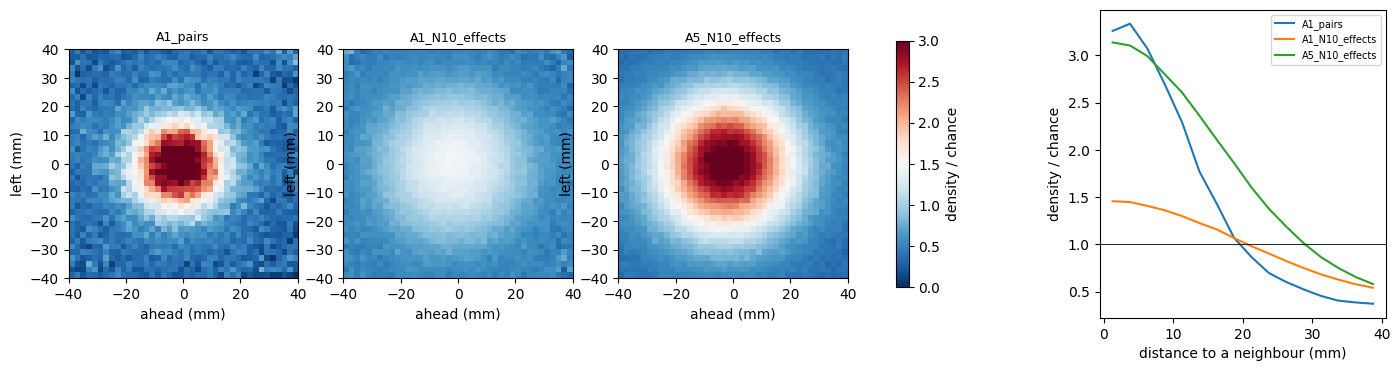

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, c in zip(axes[:3], ("A1_pairs", "A1_N10_effects", "A5_N10_effects")):
    ratio, edges, prof = P.neighbour_map(c)
    im = ax.imshow(ratio.T, origin="lower", extent=[edges[0], edges[-1], edges[0], edges[-1]], cmap="RdBu_r", vmin=0, vmax=3)
    ax.set_title(c, fontsize=9); ax.set_xlabel("ahead (mm)"); ax.set_ylabel("left (mm)")
    axes[3].plot(prof.index, prof.values, label=c)
axes[3].axhline(1, color="k", lw=0.6); axes[3].set_xlabel("distance to a neighbour (mm)"); axes[3].set_ylabel("density / chance")
axes[3].legend(fontsize=7); fig.colorbar(im, ax=axes[:3], shrink=0.8, label="density / chance")

In [ ]:
import multi_fish as MFish
Sm = json.load(open(P.OUT / "multi_fish_summary.json"))
rows = []
for c in ("A5_N10_effects", "A5_N10_effects_scrambled", "A5_N10_effects_entry", "s101_A5_N10_effects", "A1_N10_effects", "A1_N10_effects_scrambled", "s101_A1_N10_effects_scrambled"):
    d = Sm["groups"].get(c)
    if d is None:
        continue
    ct = Sm["cotravel"].get(c, {})
    rows.append({"condition": MFish.LABEL[c], "D [95% CI]": f"{d['D_mean']:+.3f} [{d['D_ci'][0]:+.3f}, {d['D_ci'][1]:+.3f}]",
                 "largest shoal (of 10)": round(d["big_mean"], 2), ">= half together": round(d["share_half_together"], 2),
                 "co-travel m / pair-h (chance)": (f"{ct['coupled']['per_pair_hour'] / 1000:.2f} ({ct['chance']['per_pair_hour'] / 1000:.2f})" if ct else "-")})
print(pd.DataFrame(rows).set_index("condition").to_string())

                                                               D [95% CI]  largest shoal (of 10)  >= half together co-travel m / pair-h (chance)
condition                                                                                                                                       
10 fish, effects (5x dish)                        -0.758 [-0.893, -0.569]                   8.27              0.88                   4.69 (1.35)
10 fish, effects, random directions (5x dish)     -0.055 [-0.072, -0.024]                   2.10              0.01                   0.30 (0.29)
10 fish, effects, onset clock on entry (5x dish)  -0.739 [-0.857, -0.559]                   8.36              0.90                   4.71 (1.42)
10 fish, effects (5x dish, seed 101)              -0.714 [-0.794, -0.635]                   8.71              0.97                   4.55 (1.21)
10 fish, effects                                  -0.200 [-0.228, -0.164]                   9.91              1.00                

<a id="s10"></a>
## 10. Robustness numbers

Four small checks the text needs.
- **Unfiltered profiles.** The profiles drop bouts whose dot centroid lies outside the dish (as for the real data). The
  same rollouts read without the filter, real and model.
- **No-radial floor.** The real-vs-real AUC without the four radial features (the floor of the no-radial reading).
- **Bits saved over the pooled marginals** (from section 1).
- **Two length scales.** The profile, attraction and two-group code converts with 3.67 px/mm, everything else with 3.60.

In [ ]:
U = P.stream_table(filtered=False); F_ = P.stream_table(filtered=True)
cols = ["dip", "plateau", "d1_plateau", "grading", "mv_err_sem", "st_err_sem"]
a = F_[F_.stream.astype(str).isin(["0"]) | (F_.model == "real")].assign(reading="filtered")
b = U[U.stream.astype(str).isin(["0"]) | (U.model == "real")].assign(reading="unfiltered")
print(pd.concat([a, b]).set_index(["reading", "model", "stream"])[cols].round(2).to_string())

                             dip  plateau  d1_plateau  grading  mv_err_sem  st_err_sem
reading    model   stream                                                             
filtered   F s0    0        3.66    17.80       22.39     5.81        0.82        0.88
           real    F s0     4.23    17.26       22.26     6.00        0.00        0.00
           F s101  0        3.42    17.98       22.19     5.58        0.85        0.96
           real    F s101   4.23    17.26       22.26     6.00        0.00        0.00
           M6 s0   0        3.70    17.79       21.65     4.67        0.90        0.80
           real    M6 s0    4.23    17.26       22.26     6.00        0.00        0.00
           M6 s101 0        3.02    17.30       20.82     4.00        1.00        1.06
           real    M6 s101  4.23    17.26       22.26     6.00        0.00        0.00
unfiltered F s0    0        2.99    19.49       24.99     7.13        0.97        0.87
           real    F s0     3.79    18.88  

In [ ]:
R = P.load("refs")["table"]
print(R.loc[["real vs real (random halves of each fish)"], ["all features", "no radial", "three heads"]].round(3).to_string())
B = P.baselines_table().reset_index()
print(B[B.model.isin(list(P.HEAD))][["seed", "model", "joint", "saved_vs_pooled_joint"]].to_string(index=False))

                                           all features  no radial  three heads
generator                                                                      
real vs real (random halves of each fish)         0.499      0.502        0.503
 seed   model      joint saved_vs_pooled_joint
    0   M6 s0  13.384777  0.798 [0.668, 0.967]
    0    F s0  13.343921  0.839 [0.693, 1.032]
  101 M6 s101  13.386681  0.809 [0.677, 0.959]
  101  F s101  13.356759  0.839 [0.694, 1.025]


In [ ]:
print(pd.DataFrame([
    {"quantity": "profiles: dip, plateau, grading, errors in mm; attraction; two-group distances", "px per mm": 3.67,
     "to the thesis scale (3.60)": "multiply by 3.67 / 3.60 = 1.0194"},
    {"quantity": "Ch. 3, individuality, multi-fish, missing-pieces sections 2, 3, 8", "px per mm": 3.60, "to the thesis scale (3.60)": "-"},
]).to_string(index=False))
print("real profile targets at 3.60: dip", round(4.23 * 1.0194, 2), "mm, plateau", round(17.26 * 1.0194, 2), "mm, grading", round(6.00 * 1.0194, 2), "mm")

                                                                      quantity  px per mm       to the thesis scale (3.60)
profiles: dip, plateau, grading, errors in mm; attraction; two-group distances       3.67 multiply by 3.67 / 3.60 = 1.0194
             Ch. 3, individuality, multi-fish, missing-pieces sections 2, 3, 8       3.60                                -
real profile targets at 3.60: dip 4.31 mm, plateau 17.59 mm, grading 6.12 mm


<a id="s11"></a>
## 11. Leave one condition out: predicting 6 moving dots

**Question.** Can the model predict a stimulus it was never
trained on? The only test of the extrapolation idea the data allow.

**What was done.** M6's exact recipe retrained at both seeds with every bout shown **6 moving dots** given zero weight in
the loss (8.0 % of bouts; the bouts stay in the records, so the history after them is real). The dot count enters as
log2(n)/3, so 6 lies between the trained 4 and 8: an interpolation in count. Read on the held-out fish: the likelihood
of the 6-moving-dot bouts (and of every other condition, as a control), the attraction per count and the matched
profile.

**How to read.** If the model generalises, the held-out condition costs little likelihood and its 6-dot response sits
where the trained one does.

In [ ]:
P.loco_table().round(4)

                bouts       M6     LOCO          LOCO - M6 [95% CI]  held_out
seed condition                                                               
s0   moving 1    5388  13.4219  13.4264  +0.0045 [-0.0125, +0.0228]     False
     moving 2    4637  13.5715  13.5785  +0.0070 [-0.0176, +0.0330]     False
     moving 4    5274  13.7042  13.7138  +0.0095 [-0.0149, +0.0326]     False
     moving 6    5585  13.7662  13.7785  +0.0123 [-0.0110, +0.0311]      True
     moving 8    4572  13.9682  13.9828  +0.0147 [-0.0163, +0.0431]     False
     no dots    30030  13.2039  13.2016  -0.0023 [-0.0179, +0.0127]     False
     static 1    4762  13.1674  13.1706  +0.0031 [-0.0194, +0.0278]     False
     static 4    4439  13.3480  13.3493  +0.0013 [-0.0285, +0.0231]     False
     static 8    4885  13.2760  13.2913  +0.0153 [-0.0125, +0.0477]     False
s101 moving 1    5388  13.4377  13.4580  +0.0202 [-0.0065, +0.0501]     False
     moving 2    4637  13.5561  13.5861  +0.0299 [-0.0081, +0.07

In [ ]:
cols = ["lik_joint", "auc_matched", "dip", "grading", "mv_err_sem", "attr_N4", "attr_N6", "attr_N8"]
rows = [dict(model=l, **{c: S(k).get(c) for c in cols}) for l, k in (("M6 s0", "26e"), ("trained without 6 moving, s0", "34e"),
                                                                     ("M6 s101", "30d"), ("trained without 6 moving, s101", "34f"))]
print(pd.DataFrame(rows).set_index("model").round(3).to_string())
print("real attraction (mm): 4 dots 5.19, 6 dots 6.43, 8 dots 6.94")

                                lik_joint  auc_matched    dip  grading  mv_err_sem  attr_N4  attr_N6  attr_N8
model                                                                                                        
M6 s0                              13.385        0.671  3.697    4.669       0.896     4.70     4.89     5.43
trained without 6 moving, s0       13.388        0.658  3.146    4.863       1.203     4.51     4.68     4.88
M6 s101                            13.387        0.645  3.015    3.997       1.001     4.91     6.41     5.77
trained without 6 moving, s101     13.401        0.631  2.941    3.623       1.248     3.52     4.62     4.57
real attraction (mm): 4 dots 5.19, 6 dots 6.43, 8 dots 6.94


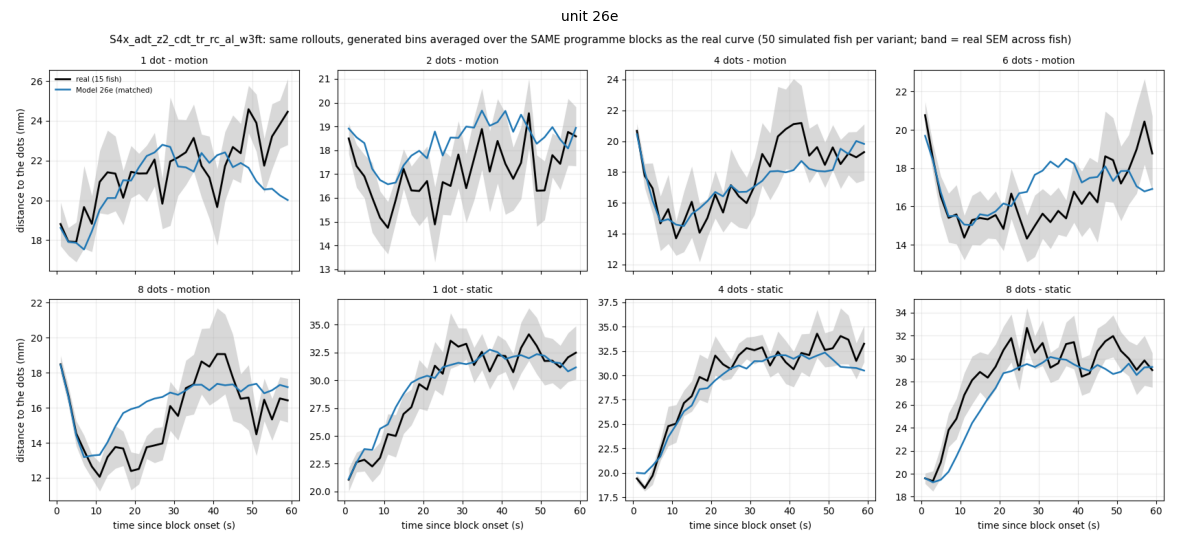

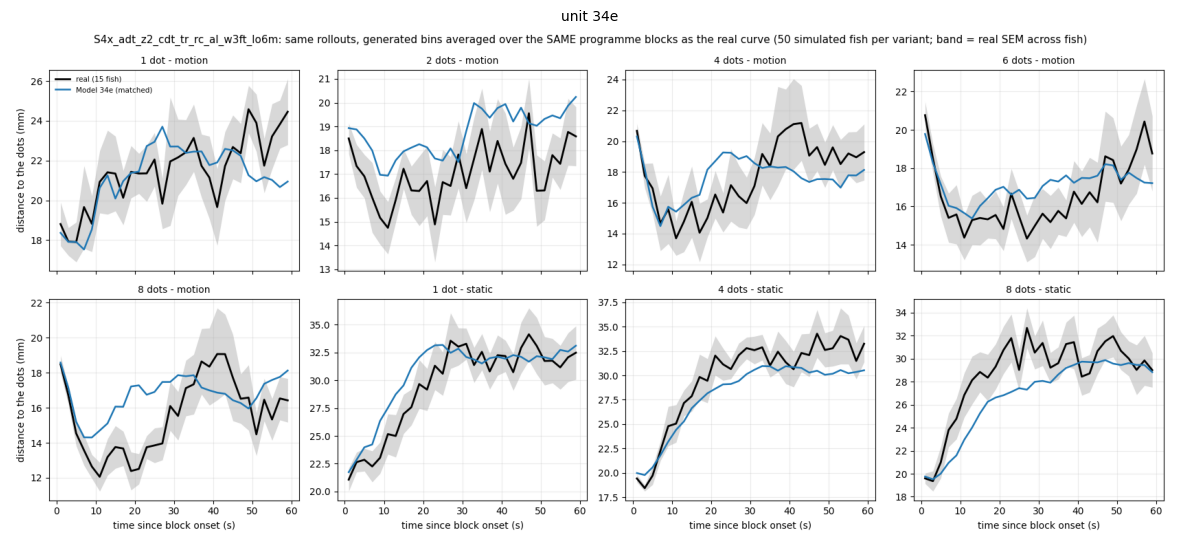

In [ ]:
# The matched profiles as saved by the units (M6 and the held-out model, seed 0): the 6-moving-dot panel is the prediction.
import base64, io
from PIL import Image
for key in ("26e", "34e"):
    blob = json.load(open(f"report_outputs/M{key}.json"))
    cell = next(c for c in blob["cells"] if c["cid"] == "matched")
    img = next(o for o in cell["outputs"] if o.get("output_type") == "display_data")
    im = Image.open(io.BytesIO(base64.b64decode(img["data"]["image/png"])))
    fig, ax = plt.subplots(figsize=(15, 6.6)); ax.imshow(im); ax.axis("off"); ax.set_title(f"unit {key}", fontsize=10)

<a id="s12"></a>
## 12. The main line at seed 101

**Question.** The main line's first steps (M1–M3) and the check M5+T existed at seed
0 only. Do they hold at seed 101?

**What was done.** M1 (= M2's weights without wall rejection), M3 and M5+T trained at seed 101 on the same recipes
(units 34a–34d), next to their seed-0 units. Steps are read within a seed. At seed 0 the M1–M3 profile numbers come
from the old rollout streams (no per-block-stream units exist for them), so across the M1–M4 rows only the likelihood
and AUC columns compare like with like at seed 0; at seed 101 every unit is on per-block streams.

In [ ]:
cols = [("lik_joint", 3), ("auc_matched", 3), ("auc_std", 3), ("dip", 2), ("grading", 2), ("mv_err_sem", 2), ("st_err_sem", 2)]
line = [("M1", "1", "34a"), ("M2", "2", "34b"), ("M3", "3", "34c"), ("M4", "20f", "30a"), ("M5", "25d", "30b"),
        ("M5+T", "29b", "34d"), ("M6", "26e", "30d")]
rows = []
for name, k0, k1 in line:
    a, b = S(k0), S(k1)
    rows.append({"model": name, **{f"{c} s0 | s101": f"{a.get(c, np.nan) if a.get(c) is not None else np.nan:.{nd}f} | {b.get(c, np.nan) if b.get(c) is not None else np.nan:.{nd}f}" for c, nd in cols}})
print(pd.DataFrame(rows).set_index("model").to_string())
print()
steps = [("M1 -> M2 (wall rejection)", "1", "2", "34a", "34b"), ("M2 -> M3 (+ latent)", "2", "3", "34b", "34c"),
         ("M3 -> M4 (s0: both on the old stream)", "3", "4", "34c", "30a"), ("M5 -> M5+T", "25d", "29b", "30b", "34d")]
rows = []
for lab, a0, b0, a1, b1 in steps:
    r = {"step": lab}
    for c, nd in cols:
        d0 = (S(b0).get(c) or np.nan) - (S(a0).get(c) or np.nan); d1 = (S(b1).get(c) or np.nan) - (S(a1).get(c) or np.nan)
        r[c] = f"{d0:+.{nd}f} | {d1:+.{nd}f}" + ("" if not (np.isfinite(d0) and np.isfinite(d1)) else ("" if np.sign(d0) == np.sign(d1) else "  (sign differs)"))
    rows.append(r)
print("steps (s0 | s101):"); print(pd.DataFrame(rows).set_index("step").to_string())

      lik_joint s0 | s101 auc_matched s0 | s101 auc_std s0 | s101 dip s0 | s101 grading s0 | s101 mv_err_sem s0 | s101 st_err_sem s0 | s101
model                                                                                                                                      
M1        13.419 | 13.453         0.869 | 0.861     0.872 | 0.869   1.05 | 0.88       1.02 | 1.74          2.51 | 2.63          3.10 | 2.49
M2        13.419 | 13.453         0.839 | 0.832     0.853 | 0.838   1.19 | 0.90       2.83 | 1.34          2.31 | 2.56          3.39 | 2.72
M3        13.361 | 13.346         0.701 | 0.708     0.707 | 0.715   0.91 | 1.03       2.62 | 2.05          2.48 | 2.58          2.84 | 2.51
M4        13.366 | 13.356         0.669 | 0.703     0.680 | 0.697   2.07 | 2.02       2.85 | 3.02          1.32 | 1.46          1.10 | 0.96
M5        13.338 | 13.390         0.648 | 0.673     0.689 | 0.663   2.68 | 2.72       4.57 | 4.89          1.01 | 1.07          1.09 | 1.20
M5+T      13.391 | 1

<a id="s13"></a>
## 13. Capacity: 64 and 256 hidden units

**Question.** Was one hidden layer of 128 units a reasonable size?

**What was done.** M6's exact recipe with 64 and with 256 hidden units, both seeds (units 34g–34j), against M6. Note: the
64-unit fits often run into the 80-epoch training limit (printed below) while the 256-unit fits stop early, so part of a
64-unit deficit can be the training budget rather than the capacity.

In [ ]:
cols = ["lik_turn", "lik_displacement", "lik_interval", "lik_joint", "auc_matched", "auc_std", "dip", "grading", "mv_err_sem", "st_err_sem"]
rows = []
for lab, k in (("64 units, s0", "34g"), ("128 units (M6), s0", "26e"), ("256 units, s0", "34i"),
               ("64 units, s101", "34h"), ("128 units (M6), s101", "30d"), ("256 units, s101", "34j")):
    rows.append(dict(model=lab, **{c: S(k).get(c) for c in cols}))
print(pd.DataFrame(rows).set_index("model").round(3).to_string())
import missing_pieces as _P
for d, lab in (("missing_ladder_checkpoints", "s0"), ("missing_seed101_ckpts", "s101")):
    try:
        man = _P.manifest(d)
        man = pd.DataFrame(man)
        print(f"epochs run ({lab}):", man.groupby("arm").epochs_run.apply(list).to_dict())
        print(f"  folds stopped by the 80-epoch limit ({lab}):", man.assign(cap=man.epochs_run >= 80).groupby("arm").cap.sum().to_dict())
    except Exception as e:
        print(lab, e)

                      lik_turn  lik_displacement  lik_interval  lik_joint  auc_matched  auc_std    dip  grading  mv_err_sem  st_err_sem
model                                                                                                                                  
64 units, s0             7.665             4.511         1.225     13.401        0.714    0.732  3.076    4.123       1.035       1.200
128 units (M6), s0       7.665             4.505         1.215     13.385        0.671    0.679  3.697    4.669       0.896       0.802
256 units, s0            7.677             4.534         1.246     13.457        0.734    0.724  2.774    4.268       1.126       1.269
64 units, s101           7.667             4.495         1.208     13.369        0.657    0.682  2.969    4.670       0.982       1.158
128 units (M6), s101     7.668             4.497         1.222     13.387        0.645    0.648  3.015    3.997       1.001       1.065
256 units, s101          7.669             4.515